### **Proyecto de la Materia de Aprendizaje Artificial**
Alumnas:

Nora Azucena Reyes Ortiz

Karla Estefania Tovar Rodríguez


#**PARTE 2. Construcción del modelo con KNN**

#5. Analizar antes de programar

**1. ¿Qué variables creen que serán más útiles para clasificar un lugar?**

Sombra, asientos e internet.

**2. ¿Qué variables podrían aportar poca información?**

Aire acondicionado, cafetería y baños cerca.

**3. ¿Existen variables con escalas numéricas muy diferentes?**

No, todas las características están codificadas con valores de 0 y 1.


**5. ¿Qué significa que dos lugares sean “cercanos” en este problema?**

En KNN, dos lugares son “cercanos” cuando tienen características similares de acuerdo con las variables evaluadas.

In [12]:
import pandas as pd
df = pd.read_csv('Dataset v1.0.csv')

**4. ¿Está balanceada la variable Apto / No apto?**
Sí, está bastante balanceada: de los 65 registros, 34 corresponden a Apto (1) y 31 a No apto (0). La diferencia entre ambas clases es de solo 3 registros. A continuacio la gráfica:


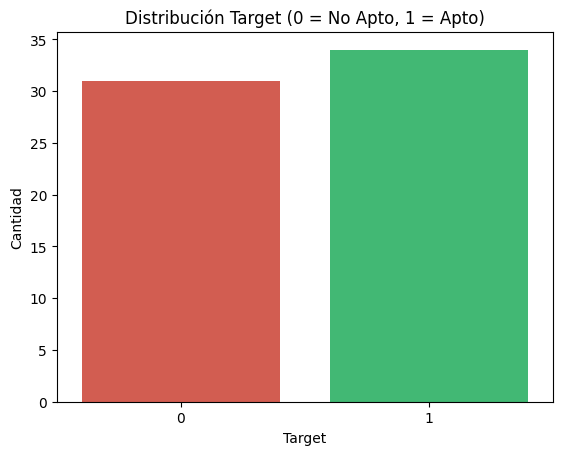

Target
1    34
0    31
Name: count, dtype: int64
Target
1    52.31%
0    47.69%
Name: proportion, dtype: object


In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Graficar sin el aviso de Seaborn
sns.countplot(x='Target', data=df, hue='Target', palette=['#e74c3c', '#2ecc71'], legend=False)

plt.title('Distribución Target (0 = No Apto, 1 = Apto)')
plt.xlabel('Target')
plt.ylabel('Cantidad')

plt.show()

# Ver conteo y porcentaje exacto
print(df['Target'].value_counts())
print((df['Target'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

# 6. Implementar KNN desde cero

In [14]:
from collections import Counter
import numpy as np


class KNNDesdeCero:

  def __init__(self, k=3):
    self.k = k

  def fit(self, X, y):
    # Guardar en memoria los datos de entrenamiento (Lazy Learner)
    self.X_train = np.array(X)
    self.y_train = np.array(y)

  # 1. Calcular la distancia euclidiana entre dos registros
  def calcular_distancia_euclidiana(self, x1, x2):
    return np.sqrt(np.sum((x1 - x2) ** 2))

  def predecir_un_registro(self, x_nuevo):

    # REQUERIMIENTO 1: Calcular distancia contra todos los de entrenamiento
    distancias = [
        self.calcular_distancia_euclidiana(x_nuevo, x_entrenamiento)
        for x_entrenamiento in self.X_train
    ]


    # REQUERIMIENTO 2: Ordenar las distancias (de menor a mayor)
    indices_ordenados = np.argsort(distancias)


    # REQUERIMIENTO 3: Seleccionar los k vecinos más cercanos
    k_indices_vecinos = indices_ordenados[: self.k]


    # REQUERIMIENTO 4: Identificar clases de los vecinos y votar por mayoría
    k_etiquetas_vecinos = [self.y_train[i] for i in k_indices_vecinos]
    conteo_votos = Counter(k_etiquetas_vecinos)


    # REQUERIMIENTO 5: Generar la predicción final
    prediccion_final = conteo_votos.most_common(1)[0][0]
    return prediccion_final

  def predict(self, X_nuevos):
    # Aplica la predicción individual a cada fila de una matriz nueva
    X_nuevos = np.array(X_nuevos)
    return np.array([self.predecir_un_registro(fila) for fila in X_nuevos])

#**PARTE 3. Experimentación**

#7. Separar entrenamiento y prueba

In [15]:
from sklearn.model_selection import train_test_split

# 1. Cargar el dataset v1.0
df = pd.read_csv('Dataset v1.0.csv')

# 2. Separar características (11 variables X) y la variable objetivo (Target y)
X = df.drop(columns=['Lugar', 'Target']).values
y = df['Target'].values

# 3. Partición 80% entrenamiento y 20% prueba con semilla fija
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

# Imprimir confirmación de la partición

print(' PUNTO 7: PARTICIÓN DEL DATASET CONSERVADA ')
print(f'Total de registros en el dataset:   {len(df)}')
print(f'Registros para Entrenamiento (80%): {len(X_train)}')
print(f'Registros para Prueba (20%):       {len(X_test)}')


 PUNTO 7: PARTICIÓN DEL DATASET CONSERVADA 
Total de registros en el dataset:   65
Registros para Entrenamiento (80%): 52
Registros para Prueba (20%):       13


#8. Experimentar con diferentes valores de k

 PUNTO 8: TABLA DE RESULTADOS DE EXPERIMENTACIÓN 
 k  Exactitud Train (%)  Exactitud Test (%) Aciertos Test
 1               100.00               84.62       11 / 13
 3                94.23               84.62       11 / 13
 5                94.23               76.92       10 / 13
 7                96.15               76.92       10 / 13
 9                94.23               76.92       10 / 13


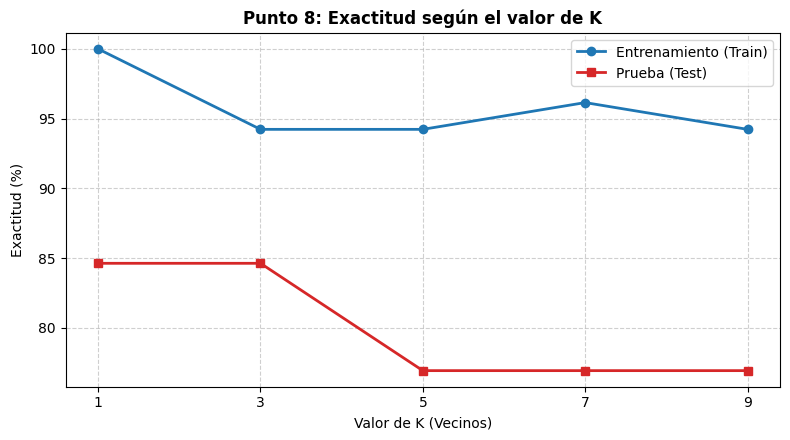

In [16]:
# 1. Definir los valores de k a evaluar
valores_k = [1, 3, 5, 7, 9]
resultados = []

# 2. Evaluar cada k usando la clase KNNDesdeCero sobre las variables del Punto 7
for k in valores_k:
    modelo = KNNDesdeCero(k=k)
    modelo.fit(X_train, y_train)

    pred_train = modelo.predict(X_train)
    pred_test = modelo.predict(X_test)

    acc_train = np.mean(pred_train == y_train) * 100
    acc_test = np.mean(pred_test == y_test) * 100
    aciertos = np.sum(pred_test == y_test)

    resultados.append({
        'k': k,
        'Exactitud Train (%)': round(acc_train, 2),
        'Exactitud Test (%)': round(acc_test, 2),
        'Aciertos Test': f"{aciertos} / {len(y_test)}"
    })

# 3. Imprimir la tabla oficial de resultados
df_resultados = pd.DataFrame(resultados)

print(" PUNTO 8: TABLA DE RESULTADOS DE EXPERIMENTACIÓN ")
print("=" * 65)
print(df_resultados.to_string(index=False))
print("=" * 65)

# 4. Generar la gráfica del Punto 8
plt.figure(figsize=(8, 4.5))
plt.plot(df_resultados['k'], df_resultados['Exactitud Train (%)'], marker='o', label='Entrenamiento (Train)', color='#1f77b4', linewidth=2)
plt.plot(df_resultados['k'], df_resultados['Exactitud Test (%)'], marker='s', label='Prueba (Test)', color='#d62728', linewidth=2)
plt.title('Punto 8: Exactitud según el valor de K', fontsize=12, fontweight='bold')
plt.xlabel('Valor de K (Vecinos)', fontsize=10)
plt.ylabel('Exactitud (%)', fontsize=10)
plt.xticks(valores_k)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.tight_layout()
plt.show()

**¿Qué efecto produjo cambiar k?**

Al aumentar k, la exactitud en prueba pasó de 84.62 % con k = 1 y 3 a 76.92 % con k = 5, 7 y 9. Esto representa una disminución de 11 a 10 aciertos de los 13 registros de prueba.

**¿El valor más grande siempre fue mejor?**

No. k = 9 obtuvo una exactitud menor que k = 1 y 3. Considerar más vecinos no necesariamente mejora la clasificación, porque puede incluir lugares menos similares al que se quiere predecir.

**¿Qué valor elegirían y por qué?**

Elegiríamos k = 3, porque alcanzó la mayor exactitud en prueba, 84.62 %, al igual que k = 1. Además, al considerar tres vecinos, la decisión depende de varios ejemplos y puede ser menos sensible a un solo registro atípico.

#9. Comparar con scikit-learn

In [17]:
# PUNTO 9: COMPARACIÓN KNN PROPIO VS SCIKIT-LEARN (PARA TODAS LAS K)

from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier

# Definir la lista de valores de k a evaluar (impares)
valores_k = [1, 3, 5, 7, 9]

registros_comparacion = []

for k in valores_k:
    # 1. Evaluar Modelo Propio (KNNDesdeCero)
    modelo_propio = KNNDesdeCero(k=k)
    modelo_propio.fit(X_train, y_train)

    pred_propio_tr = modelo_propio.predict(X_train)
    pred_propio_te = modelo_propio.predict(X_test)

    acc_propio_tr = np.mean(pred_propio_tr == y_train) * 100
    acc_propio_te = np.mean(pred_propio_te == y_test) * 100
    aciertos_propio = np.sum(pred_propio_te == y_test)

    # 2. Evaluar Modelo Scikit-Learn (KNeighborsClassifier)
    modelo_sk = KNeighborsClassifier(n_neighbors=k, metric='euclidean')
    modelo_sk.fit(X_train, y_train)

    pred_sk_tr = modelo_sk.predict(X_train)
    pred_sk_te = modelo_sk.predict(X_test)

    acc_sk_tr = accuracy_score(y_train, pred_sk_tr) * 100
    acc_sk_te = accuracy_score(y_test, pred_sk_te) * 100
    aciertos_sk = np.sum(pred_sk_te == y_test)

    # Agregar filas a la tabla
    registros_comparacion.append({
        'k': k,
        'Implementación': 'KNN Desde Cero (Propio)',
        'Exactitud Train (%)': f'{acc_propio_tr:.2f}%',
        'Exactitud Test (%)': f'{acc_propio_te:.2f}%',
        'Aciertos en Test': f'{aciertos_propio} / {len(y_test)}'
    })

    registros_comparacion.append({
        'k': k,
        'Implementación': 'KNeighborsClassifier (Scikit-Learn)',
        'Exactitud Train (%)': f'{acc_sk_tr:.2f}%',
        'Exactitud Test (%)': f'{acc_sk_te:.2f}%',
        'Aciertos en Test': f'{aciertos_sk} / {len(y_test)}'
    })

# Crear DataFrame comparativo
df_comparacion_todas_k = pd.DataFrame(registros_comparacion)

# Imprimir resultado de forma estructurada
print(' PUNTO 9: COMPARACIÓN KNN PROPIO VS SCIKIT-LEARN (TODAS LAS K) ')
print('=' * 80)
print(df_comparacion_todas_k.to_string(index=False))


 PUNTO 9: COMPARACIÓN KNN PROPIO VS SCIKIT-LEARN (TODAS LAS K) 
 k                      Implementación Exactitud Train (%) Exactitud Test (%) Aciertos en Test
 1             KNN Desde Cero (Propio)             100.00%             84.62%          11 / 13
 1 KNeighborsClassifier (Scikit-Learn)             100.00%             84.62%          11 / 13
 3             KNN Desde Cero (Propio)              94.23%             84.62%          11 / 13
 3 KNeighborsClassifier (Scikit-Learn)              98.08%             76.92%          10 / 13
 5             KNN Desde Cero (Propio)              94.23%             76.92%          10 / 13
 5 KNeighborsClassifier (Scikit-Learn)              92.31%             76.92%          10 / 13
 7             KNN Desde Cero (Propio)              96.15%             76.92%          10 / 13
 7 KNeighborsClassifier (Scikit-Learn)              92.31%             69.23%           9 / 13
 9             KNN Desde Cero (Propio)              94.23%             76.92%    

**Comparación entre KNN propio y scikit-learn**

Ambas implementaciones obtuvieron resultados similares, aunque presentaron algunas diferencias. En prueba, coincidieron para k = 1, 5 y 9, mientras que con k = 3 y 7 el KNN propio obtuvo un acierto adicional.

Una posible explicación se relaciona con la búsqueda y selección de los vecinos cuando existen distancias empatadas. Nuestra implementación calcula la distancia a todos los registros de entrenamiento y los ordena con np.argsort(). Scikit-learn utiliza métodos optimizados y, con algorithm='auto', selecciona entre fuerza bruta y árboles de búsqueda según los datos. scikit-learn 1.9.1 documentation

Como las variables son binarias, varios lugares pueden tener exactamente la misma distancia al registro evaluado. Si el empate ocurre entre el último vecino seleccionado y el siguiente, y ambos tienen clases distintas, elegir uno u otro puede cambiar la votación y la predicción. Esta es una explicación posible de las diferencias observadas; para confirmarla sería necesario comparar los vecinos seleccionados por ambos modelos.

# 10. Comparar con un modelo asignado

¿Esperan que el modelo asignado tenga un desempeño mejor, similar o peor que KNN? ¿Por qué?

Esperamos que el árbol de decisión tuviera un desempeño similar o mejor que KNN, porque las variables son binarias y podría identificar combinaciones de características que permitan distinguir entre lugares Aptos y No aptos. KNN, en cambio, utiliza la similitud entre registros y, en nuestra implementación, todas las características contribuyen por igual a la distancia.

 PUNTO 10: COMPARACIÓN FINAL CON ÁRBOL DE DECISIÓN (EQUIPO 2) 
                        Modelo Evaluado Exactitud Train (%) Exactitud Test (%) Aciertos en Test
                KNN Desde Cero (Manual)              94.23%             84.62%          11 / 13
    KNeighborsClassifier (Scikit-Learn)              98.08%             76.92%          10 / 13
Decision Tree (Equipo 2 - Scikit-Learn)             100.00%            100.00%          13 / 13

Matriz de Confusión - Árbol de Decisión (Test):
[[6 0]
 [0 7]]


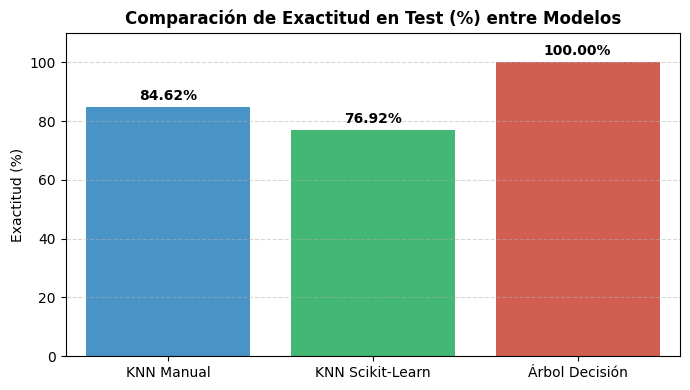

In [18]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier


# 1. Entrenar el Árbol de Decisión con la misma partición del Punto 7
modelo_arbol = DecisionTreeClassifier(random_state=42)
modelo_arbol.fit(X_train, y_train)

# Predicciones del Árbol de Decisión
pred_arbol_train = modelo_arbol.predict(X_train)
pred_arbol_test = modelo_arbol.predict(X_test)

# Métricas del Árbol de Decisión
acc_arbol_train = accuracy_score(y_train, pred_arbol_train) * 100
acc_arbol_test = accuracy_score(y_test, pred_arbol_test) * 100

# 2. Recomprobar las métricas de KNN para la tabla comparativa
modelo_knn_sk = KNeighborsClassifier(n_neighbors=3, metric='euclidean')
modelo_knn_sk.fit(X_train, y_train)
pred_knn_sk_test = modelo_knn_sk.predict(X_test)

modelo_knn_cero = KNNDesdeCero(k=3)
modelo_knn_cero.fit(X_train, y_train)
pred_knn_cero_test = modelo_knn_cero.predict(X_test)


# TABLA COMPARATIVA FINAL DE LOS 3 MODELOS

df_punto10 = pd.DataFrame({
    'Modelo Evaluado': [
        'KNN Desde Cero (Manual)',
        'KNeighborsClassifier (Scikit-Learn)',
        'Decision Tree (Equipo 2 - Scikit-Learn)',
    ],
    'Exactitud Train (%)': [
        f'{accuracy_score(y_train, modelo_knn_cero.predict(X_train))*100:.2f}%',
        f'{accuracy_score(y_train, modelo_knn_sk.predict(X_train))*100:.2f}%',
        f'{acc_arbol_train:.2f}%',
    ],
    'Exactitud Test (%)': [
        f'{accuracy_score(y_test, pred_knn_cero_test)*100:.2f}%',
        f'{accuracy_score(y_test, pred_knn_sk_test)*100:.2f}%',
        f'{acc_arbol_test:.2f}%',
    ],
    'Aciertos en Test': [
        f'{np.sum(pred_knn_cero_test == y_test)} / {len(y_test)}',
        f'{np.sum(pred_knn_sk_test == y_test)} / {len(y_test)}',
        f'{np.sum(pred_arbol_test == y_test)} / {len(y_test)}',
    ],
})

print(' PUNTO 10: COMPARACIÓN FINAL CON ÁRBOL DE DECISIÓN (EQUIPO 2) ')
print('=' * 75)
print(df_punto10.to_string(index=False))
print('=' * 75)

# Matriz de Confusión del Árbol de Decisión
print('\nMatriz de Confusión - Árbol de Decisión (Test):')
print(confusion_matrix(y_test, pred_arbol_test))


# GRAFICA COMPARATIVA DE EXACTITUD EN TEST (LOS 3 MODELOS)
modelos = [
    'KNN Manual',
    'KNN Scikit-Learn',
    'Árbol Decisión',
]
exactitudes_test = [
    accuracy_score(y_test, pred_knn_cero_test) * 100,
    accuracy_score(y_test, pred_knn_sk_test) * 100,
    acc_arbol_test,
]

plt.figure(figsize=(7, 4))
ax = sns.barplot(
    x=modelos,
    y=exactitudes_test,
    hue=modelos,
    palette=['#3498db', '#2ecc71', '#e74c3c'],
    legend=False,
)

# Agregar las etiquetas numéricas encima de cada barra
for p in ax.patches:
    altura = p.get_height()
    ax.annotate(
        f'{altura:.2f}%',
        (p.get_x() + p.get_width() / 2.0, altura),
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        xytext=(0, 3),
        textcoords='offset points',
    )

plt.title(
    'Comparación de Exactitud en Test (%) entre Modelos',
    fontsize=12,
    fontweight='bold',
)
plt.ylabel('Exactitud (%)')
plt.ylim(0, 110)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

**¿KNN propio y KNN de scikit-learn produjeron resultados similares?**

Con k = 3, ambos obtuvieron resultados cercanos, aunque no idénticos. El KNN propio alcanzó 84.62 % de exactitud en prueba, con 11 de 13 aciertos, mientras que scikit-learn obtuvo 76.92 %, con 10 de 13 aciertos. La diferencia podría relacionarse con la selección de vecinos cuando existen distancias empatadas.

**¿Cómo se comportó el modelo asignado respecto a KNN?**

El árbol de decisión obtuvo el mejor resultado en esta división de datos: alcanzó 100 % de exactitud en entrenamiento y prueba, clasificando correctamente los 13 registros de prueba. La matriz de confusión muestra que identificó correctamente 6 lugares No aptos y 7 Aptos, sin errores.

**¿Los resultados coincidieron con su predicción inicial?**

Si nuestra expectativa era que el árbol tendría un desempeño similar o mejor que KNN, los resultados fueron consistentes con ella, ya que superó a ambas implementaciones en el conjunto de prueba.
**¿Qué características de los datos podrían explicar las diferencias observadas?**

Las variables binarias podrían facilitar que el árbol identifique reglas basadas en combinaciones específicas de características. Además, puede utilizar las variables que mejor separan las clases, mientras que KNN calcula la distancia considerando todas las características. En KNN, la presencia de registros con distancias iguales también podría influir en los vecinos seleccionados y en la votación final.
Aunque el árbol obtuvo 100 %, este resultado corresponde a 13 registros de prueba. Sería necesario evaluarlo con más datos o mediante validación cruzada para comprobar si mantiene ese desempeño.